# 🧠 MLLM Baseline Evaluation for Graph Property Classification

## Two Experiments

| Experiment | YES samples | NO samples | Prompt uses |
|------------|-------------|------------|-------------|
| **Exp1** | yes | s_no | yes + s_no rules |
| **Exp2** | yes | d_no | yes + d_no rules |

## Visual Proof Effect
**Visual Proof Gain** = Acc(Exp2) - Acc(Exp1)

Positive gain → d_no is easier to classify than s_no

---

## 📦 Step 1: Install Dependencies

In [1]:
# ============================================================================
# STEP 1: Install Dependencies (Kaggle/Colab)
# ============================================================================

# IMPORTANT: Even if using local model weights, we MUST update transformers
# because Qwen3-VL architecture support was added in very recent versions (>=4.57.0)
!pip install git+https://github.com/huggingface/transformers.git -q

# Install other dependencies
!pip install accelerate torch torchvision pillow -q
!pip install "qwen-vl-utils>=0.0.14" -q

# Note: flash-attn is OPTIONAL - model works without it using eager attention
print("✓ Dependencies installed - transformers from GitHub (latest)")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.2/625.2 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 88.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.1.1 requires transformers<5.0.0,>=4.41.0, but you have transformers 5.5.0.dev0 which is incompatible.
gradio 5.49.1 requires pydantic<2.12,>=2.0, but you have pydantic 2.12.5 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 59.0 MB/s eta 0:00:00
✓ Dependencies installed - transformers from GitHub (latest)


## 📚 Step 2: Import Libraries

Import necessary libraries for:
- **Transformers**: Qwen2.5-VL model and processor
- **Image Processing**: PIL for loading graph images
- **Data Handling**: Pandas, NumPy for results management
- **Visualization**: Matplotlib, Seaborn for metrics plots
- **Evaluation**: Scikit-learn for accuracy, precision, recall, F1

In [2]:
# ============================================================================
# STEP 2: Import Libraries
# ============================================================================

import os
import json
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
from typing import Dict, List, Tuple
import warnings
warnings.filterwarnings('ignore')

import torch

# Import Qwen model - use AutoModelForImageTextToText for Qwen3-VL
# Falls back gracefully if flash-attn not available
from transformers import AutoModelForImageTextToText, AutoProcessor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch version: 2.8.0+cu126
CUDA available: True
CUDA device: Tesla T4
GPU Memory: 15.6 GB


## 🔍 Step 3: Explore Kaggle Input

Explore the dataset structure on Kaggle to understand:
- Available graph properties (9 total)
- Image organization (yes/no folders per property)
- Sample counts and file formats

In [3]:
# ============================================================================
# STEP 3: Explore Kaggle Input (Find Dataset Path)
# ============================================================================

def explore_kaggle_input(base_path='/kaggle/input', max_depth=2):
    """Explore the Kaggle input directory structure."""
    if not os.path.exists(base_path):
        print(f"⚠️  Path does not exist: {base_path}")
        print(f"   Running locally - using local path")
        return
    
    print(f"📁 Exploring: {base_path}")
    print("=" * 60)
    
    for root, dirs, files in os.walk(base_path):
        depth = root.replace(base_path, '').count(os.sep)
        if depth > max_depth:
            continue
        indent = '  ' * depth
        print(f"{indent}📂 {os.path.basename(root)}/")
        
        if depth <= max_depth:
            for f in files[:3]:  # Show first 3 files
                print(f"{indent}  📄 {f}")
            if len(files) > 3:
                print(f"{indent}  ... and {len(files)-3} more files")

explore_kaggle_input()

📁 Exploring: /kaggle/input
📂 input/
  📂 datasets/
    📂 ahmmadnurswapnil/


## ⚙️ Step 4: Configuration

Configure evaluation parameters:
- **Model**: Qwen2.5-VL-8B-Instruct (latest open-source MLLM)
- **Dataset Path**: Kaggle input directory
- **Properties**: All 9 graph properties to evaluate
- **Samples**: Number of images per category

In [4]:
# ============================================================================
# STEP 4: Configuration
# ============================================================================

class Config:
    # Dataset path - UPDATE THIS FOR YOUR ENVIRONMENT
    # DATASET_ROOT = '../data_generator/graphtrails_dataset'  # Local
    DATASET_ROOT = '/kaggle/input/datasets/ahmmadnurswapnil/graph-visualization/graphtrails_dataset'  # Kaggle
    
    # Model settings - Qwen3-VL (Latest as of 2025)
    # We prioritize the local Kaggle input if available to save download time
    HF_MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
    MODEL_NAME = HF_MODEL_ID  # Default to HF
    
    # Auto-detect local model path in Kaggle input
    if os.path.exists('/kaggle/input'):
        # Look for Qwen3 VL folder
        candidates = [d for d in os.listdir('/kaggle/input') if 'qwen' in d.lower() and '3' in d and 'vl' in d]
        # Sort by length to find most specific match or just pick first valid one
        for d in candidates:
            path = os.path.join('/kaggle/input', d)
            # Check if it looks like a model (has config.json)
            if os.path.exists(os.path.join(path, 'config.json')):
                MODEL_NAME = path
                break
            # Check for nested structure (common in Kaggle Models)
            # e.g. /kaggle/input/qwen3-vl/transformers/8b-instruct/1
            for root, dirs, files in os.walk(path):
                if 'config.json' in files:
                    MODEL_NAME = root
                    break
            if MODEL_NAME != HF_MODEL_ID:
                break
    
    # All properties to evaluate
    ALL_PROPERTIES = [
        'cut_vertex', 'connectivity', 'bipartite', 'planarity',
        'outer_planarity', 'hamiltonian', 'k_colorability',
        'completeness'
    ]
    
    # Evaluation settings
    MAX_SAMPLES_PER_CLASS = 200  # Limit samples per class (YES/s_no/d_no) for speed
    BATCH_SIZE = 1  # Process one image at a time for MLLM
    
    # Device
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    
    # Output
    RESULTS_DIR = './mllm_eval_results'
    
    # Random seed for reproducibility
    SEED = 42

config = Config()
os.makedirs(config.RESULTS_DIR, exist_ok=True)

print(f"Configuration:")
print(f"  Dataset: {config.DATASET_ROOT}")
print(f"  Model Path: {config.MODEL_NAME}")
print(f"  Source: {'Local Kaggle Input' if config.MODEL_NAME != config.HF_MODEL_ID else 'Hugging Face Hub'}")
print(f"  Device: {config.DEVICE}")
print(f"  Properties: {len(config.ALL_PROPERTIES)}")

# Verify dataset exists
if os.path.exists(config.DATASET_ROOT):
    print(f"  ✓ Dataset path exists")
else:
    print(f"  ⚠️ Dataset path NOT found - please update DATASET_ROOT")

Configuration:
  Dataset: /kaggle/input/datasets/ahmmadnurswapnil/graph-visualization/graphtrails_dataset
  Model Path: Qwen/Qwen2.5-VL-3B-Instruct
  Source: Hugging Face Hub
  Device: cuda
  Properties: 8
  ✓ Dataset path exists


## 🔑 Step 5: Define Visual Certificates

These **visual certificates** describe exactly how each graph property is visualized.  
They are sent to the MLLM along with each image to provide context for classification.

Each certificate includes:
- **Visualization Type**: Node-link diagram, adjacency matrix, or book layout
- **Color Scheme**: TEAL (#4ECDC4), RED (#FF6B6B), GRAY (#666666)
- **Visual Indicators**: What patterns indicate YES vs NO

In [5]:
    
# ============================================================================
# STEP 5: Define Visual Certificate Descriptions (3-CLASS: yes, s_no, d_no)
# ============================================================================
# Based on Plan.md - correct visual strategies for each class

VISUAL_CERTIFICATES = {
    'cut_vertex': {
        'name': 'Cut Vertex',
        'yes': 'YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.',
        's_no': 'NO if: Same bridge-like layout, but dense clusters have edges between them (2-connected, no cut vertex).',
        'd_no': 'NO if: Ear decomposition (flower pattern) with ears spreading around central path, proving 2-connectivity.'
    },
    
    'connectivity': {
        'name': 'Graph Connectivity',
        'yes': 'YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.',
        's_no': 'NO if: BFS tree on concentric circles but BOLD spanning tree only covers maximum component (not all components).',
        'd_no': 'NO if: Spatially SEPARATED clusters with clear visible gaps between them, showing disconnection.'
    },
    
    'bipartite': {
        'name': 'Bipartite Graph',
        'yes': 'YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.',
        's_no': 'NO if: Matrix sorted into 2 blocks on diagonal, but diagonal blocks HAVE edges inside (colored cells in diagonal blocks, not all empty).',
        'd_no': 'NO if: Odd cycle HIGHLIGHTED in top-left block. Cycle nodes connected sequentially forming odd-length closed path.'
    },
    
    'planarity': {
        'name': 'Planarity',
        'yes': 'YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.',
        's_no': 'NO if: Same spread layout style as YES, but some edges visibly CROSS each other (non-planar edges).',
        'd_no': 'NO if: BOLD edges highlight K₅ (pentagon with all diagonals) or K₃,₃ (bipartite 3+3) minor proving non-planarity.'
    },
    
    'outer_planarity': {
        'name': 'Outer-Planarity',
        'yes': 'YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.',
        's_no': 'NO if: Outer-planar style layout but some edges visibly CROSS each other.',
        'd_no': 'NO if: BOLD edges highlight K₄ (4 nodes fully connected) or K₂,₃ (2+3 bipartite) minor proving non-outer-planarity.'
    },
    
    'hamiltonian': {
        'name': 'Hamiltonian Cycle',
        'yes': 'YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.',
        's_no': 'NO if: Longest cycle on outer circle (LOOKS like Hamiltonian) but some nodes are INSIDE the cycle.',
        'd_no': 'NO if: Cut-set (S) shown as BOLD highlighted nodes at center. k(G-S) > |S| proving no Hamiltonian cycle.'
    },
    
    'k_colorability': {
        'name': '4-Colorability',
        'yes': 'YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.',
        's_no': 'NO if: Matrix with >4 EMPTY diagonal blocks (5-8 blocks visible on diagonal), needs more than 4 colors.',
        'd_no': 'NO if: Matrix with highlighted K₅/K₆/K₇/K₈ clique (BOLD highlighted edges forming complete subgraph in top-left block). Except diagonal, every cell in top-left block is filled, showing large clique.'
    },
    
    'completeness': {
        'name': 'Graph Completeness',
        'yes': 'YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).',
        's_no': 'NO if: There are some missing edges (empty cells outside diagonal) in the adjacency matrix, showing it is not complete.',
        'd_no': 'NO if: Nodes are sorted by degree (most connected to least). Matrix shows density gradient: dense/filled top-left region fading to sparse/empty bottom-right, proving that not all node pairs are connected.'
    }
}

print(f"✓ Loaded {len(VISUAL_CERTIFICATES)} visual certificates (yes/s_no/d_no)")
for prop, cert in VISUAL_CERTIFICATES.items():
    print(f"  - {prop}: {cert['name']}")

✓ Loaded 8 visual certificates (yes/s_no/d_no)
  - cut_vertex: Cut Vertex
  - connectivity: Graph Connectivity
  - bipartite: Bipartite Graph
  - planarity: Planarity
  - outer_planarity: Outer-Planarity
  - hamiltonian: Hamiltonian Cycle
  - k_colorability: 4-Colorability
  - completeness: Graph Completeness


## 🤖 Step 6: Load Qwen2.5-VL Model

Load the **Qwen2.5-VL-3B-Instruct** model:
- Uses `eager` attention implementation (no flash-attn dependency)
- Loads with `bfloat16` precision for memory efficiency
- Auto device mapping for GPU utilization

In [6]:
# ============================================================================
# STEP 6: Load Qwen3-VL Model
# ============================================================================

print(f"Loading model: {config.MODEL_NAME}")
print("This may take a few minutes...")

# Load Qwen3-VL model WITHOUT flash-attention (to avoid CUDA compatibility issues)
model = AutoModelForImageTextToText.from_pretrained(
    config.MODEL_NAME,
    torch_dtype=torch.float16,  # Use FP16 to save memory
    device_map="auto",  # Automatically distribute across GPUs
    trust_remote_code=True,
    attn_implementation="eager"  # Use eager attention instead of flash-attn
)

# Load processor (handles image + text input)
processor = AutoProcessor.from_pretrained(
    config.MODEL_NAME,
    trust_remote_code=True
)

print(f"✓ Model loaded successfully!")
print(f"  Model type: {type(model).__name__}")
if torch.cuda.is_available():
    print(f"  GPU Memory used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Loading model: Qwen/Qwen2.5-VL-3B-Instruct
This may take a few minutes...


config.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

✓ Model loaded successfully!
  Model type: Qwen2_5_VLForConditionalGeneration
  GPU Memory used: 3.66 GB


## 🎯 Step 7: Evaluation Function

The `evaluate_graph_property()` function:
1. Loads the graph image
2. Constructs a prompt with the visual certificate
3. Asks the model: "Does this graph have [property]? Answer YES or NO."
4. Parses the model's response to extract YES/NO answer

In [7]:
# ============================================================================
# STEP 7: Create MLLM Evaluation Function
# ============================================================================

def evaluate_graph_property(image_path: str, property_name: str, exp_no_type: str, model, processor) -> Tuple[str, float, str, str]:
    """
    Use MLLM to evaluate if a graph image has a specific property.
    
    Args:
        image_path: Path to the graph image
        property_name: Name of the property to evaluate
        exp_no_type: 's_no' or 'd_no' - the NO type for this EXPERIMENT (not sample)
        model: Qwen-VL model
        processor: Qwen-VL processor
    
    Returns:
        prediction: 'YES' or 'NO'
        confidence: Confidence score (0-1)
        response: Full model response text
        prompt: The prompt used
    """
    cert = VISUAL_CERTIFICATES[property_name]
    
    # Use EXPERIMENT's no_type for prompt (not sample_type)
    # Exp1: always use s_no rule | Exp2: always use d_no rule
    yes_rule = cert['yes']
    no_rule = cert[exp_no_type]
    
    prompt = f'''Property: {cert['name']}

Rules:
- {yes_rule}
- {no_rule}

Question: Does this graph have {cert['name']}? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]'''
    
    image = Image.open(image_path).convert('RGB')
    
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt}
            ]
        }
    ]
    
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(
        text=[text],
        images=[image],
        return_tensors="pt",
        padding=True
    ).to(model.device)
    
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False,
            pad_token_id=processor.tokenizer.pad_token_id
        )
    
    response = processor.decode(outputs[0], skip_special_tokens=True)
    
    if "assistant" in response.lower():
        response = response.split("assistant")[-1].strip()
    
    response_upper = response.upper()
    if response_upper.startswith('YES') or 'YES:' in response_upper[:10] or 'YES,' in response_upper[:10]:
        prediction = 'YES'
        confidence = 0.8
    elif response_upper.startswith('NO') or 'NO:' in response_upper[:10] or 'NO,' in response_upper[:10]:
        prediction = 'NO'
        confidence = 0.8
    else:
        if 'YES' in response_upper[:100]:
            prediction = 'YES'
            confidence = 0.6
        elif 'NO' in response_upper[:100]:
            prediction = 'NO'
            confidence = 0.6
        else:
            prediction = 'NO'
            confidence = 0.3
    
    return prediction, confidence, response, prompt

print("✓ Evaluation function defined (uses exp_no_type for consistent prompts)")

✓ Evaluation function defined (uses exp_no_type for consistent prompts)


## 🧪 Step 7.1: Manual Testing (Optional)

Test the evaluation function on individual images before running the full dataset.

**Try different combinations:**
- Different properties (cut_vertex, connectivity, planarity, etc.)
- Different images (yes/no examples)
- Compare model responses

This helps verify the visual certificates and model behavior.

MANUAL TEST: hamiltonian | yes
Expected: YES


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



📝 PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Cut-set (S) shown as BOLD highlighted nodes at center. k(G-S) > |S| proving no Hamiltonian cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]

🤖 RESPONSE:
YES: The graph has a Hamiltonian cycle. The highlighted edges form a cycle that visits all the nodes in the outer circle, satisfying the condition for a Hamiltonian cycle.

Prediction: YES | Correct: ✓


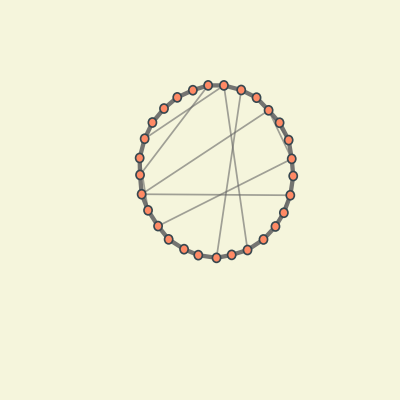

In [8]:
# ============================================================================
# MANUAL TEST: Single Image Evaluation
# ============================================================================

TEST_PROPERTY = 'hamiltonian'
TEST_TYPE = 'yes'  # 'yes', 's_no', or 'd_no'
IMAGE_NUM = '001'
PROPERTY_TYPE = 'd_no'
TEST_IMAGE_PATH = f'{config.DATASET_ROOT}/{TEST_PROPERTY}/{TEST_TYPE}/{TEST_PROPERTY}_{TEST_TYPE}_{IMAGE_NUM}.png'

if os.path.exists(TEST_IMAGE_PATH):
    print(f"MANUAL TEST: {TEST_PROPERTY} | {TEST_TYPE}")
    print(f"Expected: {'YES' if TEST_TYPE == 'yes' else 'NO'}")
    
    prediction, confidence, response, prompt = evaluate_graph_property(
        TEST_IMAGE_PATH, TEST_PROPERTY, PROPERTY_TYPE, model, processor
    )
    
    print(f"\n📝 PROMPT:\n{prompt}")
    print(f"\n🤖 RESPONSE:\n{response[:500]}")
    print(f"\nPrediction: {prediction} | Correct: {'✓' if prediction == ('YES' if TEST_TYPE == 'yes' else 'NO') else '✗'}")
    
    from IPython.display import display
    display(Image.open(TEST_IMAGE_PATH))
else:
    print(f"⚠️ Test image not found: {TEST_IMAGE_PATH}")

## 📂 Step 8: Load Dataset

Load samples for **two experiments**:
- **Same Layout**: yes + s_no (deceptive negatives)
- **Different Layout**: yes + d_no (visual certificates)

In [9]:
# ============================================================================
# STEP 8: Load Dataset (TWO EXPERIMENTS)
# ============================================================================

def load_dataset_by_layout(dataset_root: str, properties: List[str], no_type: str, max_per_class: int = 50):
    """
    Load dataset for specific experiment.
    
    Args:
        no_type: 's_no' or 'd_no'
    Returns:
        samples: List of (image_path, property_name, true_label, sample_type)
    """
    samples = []
    
    for prop in properties:
        prop_dir = os.path.join(dataset_root, prop)
        if not os.path.exists(prop_dir):
            continue
        
        # Load YES samples (label=1, sample_type='yes')
        yes_dir = os.path.join(prop_dir, 'yes')
        if os.path.exists(yes_dir):
            for f in os.listdir(yes_dir)[:max_per_class]:
                if f.endswith('.png'):
                    samples.append((os.path.join(yes_dir, f), prop, 1, 'yes'))
        
        # Load NO samples (label=0, sample_type=no_type)
        no_dir = os.path.join(prop_dir, no_type)
        if os.path.exists(no_dir):
            for f in os.listdir(no_dir)[:max_per_class]:
                if f.endswith('.png'):
                    samples.append((os.path.join(no_dir, f), prop, 0, no_type))
    
    return samples

# Load BOTH experiments
print(f"Loading datasets from: {config.DATASET_ROOT}\n")

samples_same = load_dataset_by_layout(config.DATASET_ROOT, config.ALL_PROPERTIES, 's_no', config.MAX_SAMPLES_PER_CLASS)
samples_diff = load_dataset_by_layout(config.DATASET_ROOT, config.ALL_PROPERTIES, 'd_no', config.MAX_SAMPLES_PER_CLASS)

print(f"📊 Experiment 1 (yes + s_no): {len(samples_same)} samples")
print(f"📊 Experiment 2 (yes + d_no): {len(samples_diff)} samples")

Loading datasets from: /kaggle/input/datasets/ahmmadnurswapnil/graph-visualization/graphtrails_dataset

📊 Experiment 1 (yes + s_no): 3200 samples
📊 Experiment 2 (yes + d_no): 3200 samples


## 🚀 Step 9: Run Evaluation

Run MLLM on **both experiments**:
1. Same Layout (yes vs s_no)
2. Different Layout (yes vs d_no)

In [10]:
# ============================================================================
# STEP 9: Run MLLM Evaluation (TWO EXPERIMENTS)
# ============================================================================

def run_evaluation(samples, exp_no_type, experiment_name):
    """
    Run evaluation on samples.
    
    Args:
        samples: List of (image_path, property_name, true_label, sample_type)
        exp_no_type: 's_no' or 'd_no' - determines which rules to use in ALL prompts
        experiment_name: For progress bar
    """
    results = []
    for img_path, prop_name, true_label, sample_type in tqdm(samples, desc=experiment_name):
        try:
            pred, conf, resp, prompt = evaluate_graph_property(img_path, prop_name, exp_no_type, model, processor)
            pred_label = 1 if pred == 'YES' else 0
            results.append({
                'image_path': img_path, 'property': prop_name,
                'true_label': true_label, 'pred_label': pred_label,
                'prediction': pred, 'sample_type': sample_type,
                'exp_no_type': exp_no_type,
                'prompt': prompt,
                'response': resp
            })
        except Exception as e:
            results.append({
                'image_path': img_path, 'property': prop_name,
                'true_label': true_label, 'pred_label': -1,
                'prediction': 'ERROR', 'sample_type': sample_type,
                'exp_no_type': exp_no_type,
                'prompt': 'ERROR',
                'response': str(e)
            })
        if len(results) % 20 == 0 and torch.cuda.is_available():
            torch.cuda.empty_cache()
    return results

print("="*60)
print("EXPERIMENT 1: yes + s_no (prompt uses s_no rules)")
print("="*60)
results_same = run_evaluation(samples_same, 's_no', "Experiment 1")

print("\n" + "="*60)
print("EXPERIMENT 2: yes + d_no (prompt uses d_no rules)")
print("="*60)
results_diff = run_evaluation(samples_diff, 'd_no', "Experiment 2")

print(f"\n✓ Both experiments complete")

EXPERIMENT 1: yes + s_no (prompt uses s_no rules)


Experiment 1: 100%|██████████| 3200/3200 [2:16:48<00:00,  2.57s/it]



EXPERIMENT 2: yes + d_no (prompt uses d_no rules)


Experiment 2: 100%|██████████| 3200/3200 [2:50:55<00:00,  3.20s/it]


✓ Both experiments complete


## 🔍 Step 9.1: Verify Prompts & Responses

Inspect prompts and responses to verify correct experimental setup.


████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  CUT_VERTEX  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Same bridge-like layout, but dense clusters have edges between them (2-connected, no cut vertex).

Question: Does this graph have Cut Vertex? Answer YES or NO

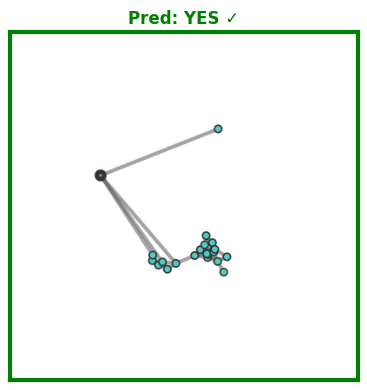


🤖 RESPONSE:
YES: The graph has a bold highlighted cut-vertex at the bridge position, connecting two dense separate clusters.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Ear decomposition (flower pattern) with ears spreading around central path, proving 2-connectivity.

Question: Does this graph have Cut Vertex? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


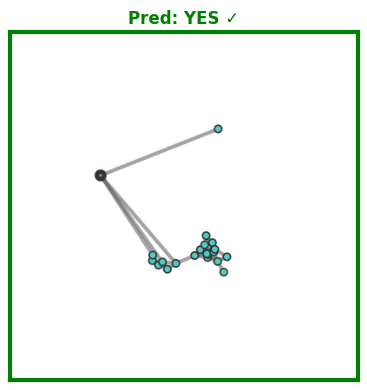


🤖 RESPONSE:
YES: The graph has a bold highlighted cut-vertex at the bridge position, connecting two dense separate clusters. This indicates that removing this vertex will disconnect the graph into two parts, satisfying the definition of a cut-vertex.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Same bridge-like layout, but dense clusters have edges between them (2-connected, no cut vertex).

Question: Does this graph have Cut Vertex? Ans

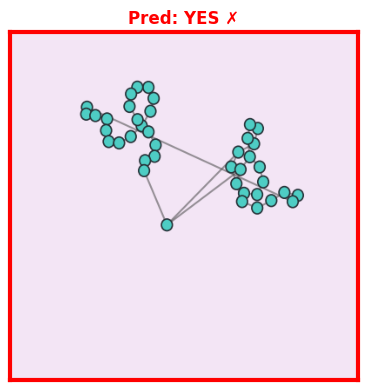


🤖 RESPONSE:
YES: The graph has a bold highlighted cut-vertex at the bridge position, connecting two dense separate clusters.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Cut Vertex

Rules:
- YES if: BOLD highlighted cut-vertex at bridge position, connecting two dense separate clusters.
- NO if: Ear decomposition (flower pattern) with ears spreading around central path, proving 2-connectivity.

Question: Does this graph have Cut Vertex? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


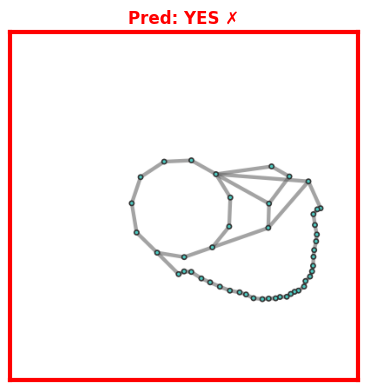


🤖 RESPONSE:
YES: The graph has a bold highlighted cut-vertex at the bridge position, connecting two dense separate clusters. This indicates that removing this vertex will disconnect the graph into more than one component, fulfilling the criteria for a cut-vertex.

████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  CONNECTIVITY  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Graph Connectivit

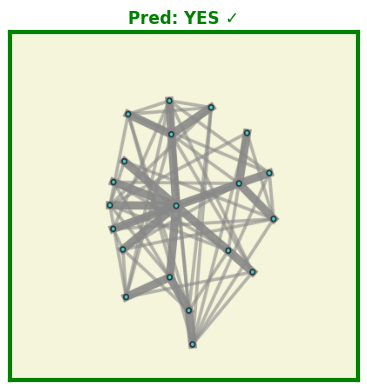


🤖 RESPONSE:
YES: The graph has Graph Connectivity because the BFS tree on concentric circles with bold spanning tree edges in a single component graph is present, indicating that there is a spanning tree covering all nodes in one connected component.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Graph Connectivity

Rules:
- YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.
- NO if: Spatially SEPARATED clusters with clear visible gaps between them, showing disconnection.

Question: Does this graph have Graph Connectivity? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


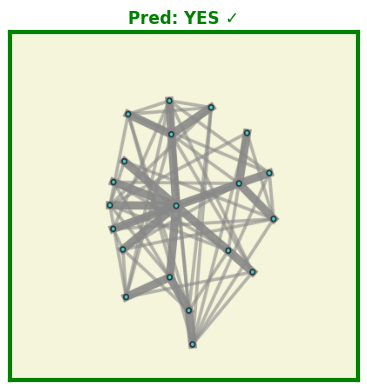


🤖 RESPONSE:
YES: The graph has Graph Connectivity because it forms a single connected component where a BFS (Breadth-First Search) tree can be drawn on concentric circles without any gaps, indicating that there is a spanning tree that connects all nodes in the graph.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Graph Connectivity

Rules:
- YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.
- NO if: BFS tree on concentric circles but BOLD spanning tree only covers maximum component (not all components).

Question: D

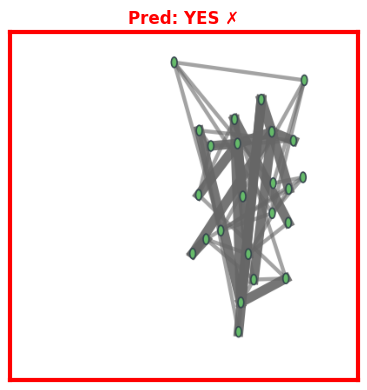


🤖 RESPONSE:
YES: The graph has Graph Connectivity because the BFS tree on concentric circles covers all components of the graph, including the bold spanning tree edges which form a single connected component.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Graph Connectivity

Rules:
- YES if: BFS tree on concentric circles with BOLD spanning tree edges in a single component graph.
- NO if: Spatially SEPARATED clusters with clear visible gaps between them, showing disconnection.

Question: Does this graph have Graph Connectivity? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


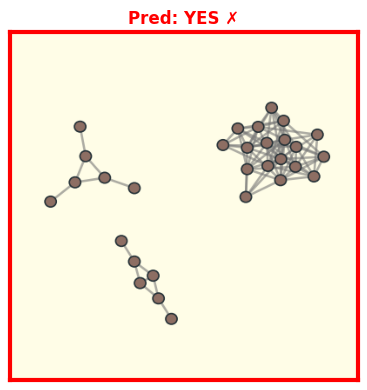


🤖 RESPONSE:
YES: The graph has Graph Connectivity because it can be traversed from any node to any other node using a single connected component without any gaps or isolated clusters.

████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  BIPARTITE  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right bl

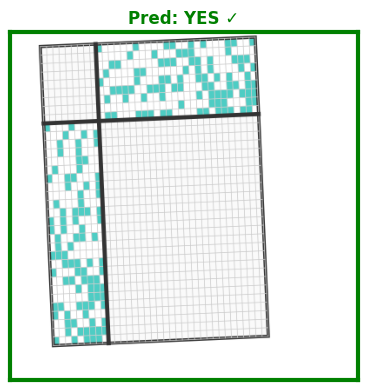


🤖 RESPONSE:
YES: The matrix has two empty diagonal blocks (top-left and bottom-right blocks) that show two independent sets of nodes. There are no colored cells within the diagonal blocks, indicating that the graph is bipartite.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Odd cycle HIGHLIGHTED in top-left block. Cycle nodes connected sequentially forming odd-length closed path.

Question: Does this graph have Bipartite Graph? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


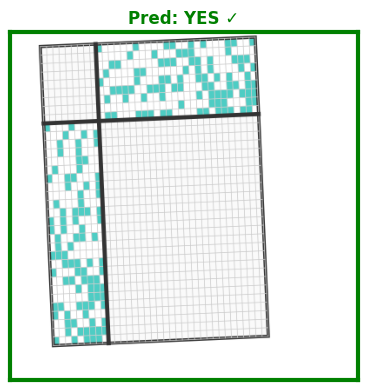


🤖 RESPONSE:
YES: The matrix has two empty diagonal blocks, indicating two independent sets of nodes. There is no cycle highlighted in the top-left block that would violate the bipartite property.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Matrix sorted into 2 blocks on diagonal, but diagonal blocks HAVE edges inside (colored cells in diagonal blocks, not all empty).

Question: Does this graph ha

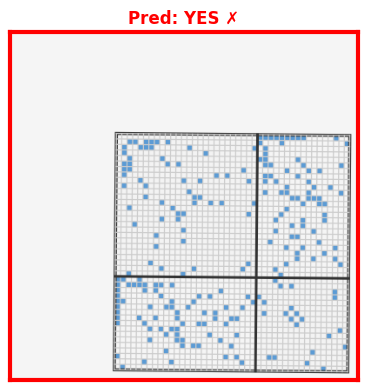


🤖 RESPONSE:
YES: The matrix has two empty diagonal blocks (top-left and bottom-right blocks) that do not contain any filled cells, indicating two independent sets of nodes.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Bipartite Graph

Rules:
- YES if: Matrix has two EMPTY diagonal blocks (top-left and bottom-right blocks have no filled cells), showing two independent sets.
- NO if: Odd cycle HIGHLIGHTED in top-left block. Cycle nodes connected sequentially forming odd-length closed path.

Question: Does this graph have Bipartite Graph? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


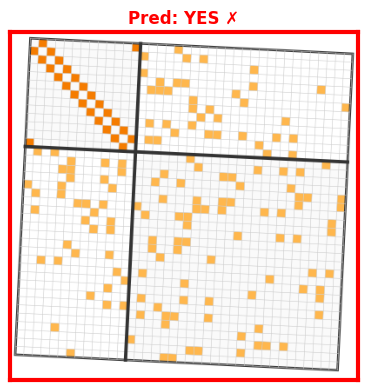


🤖 RESPONSE:
YES: The matrix has two empty diagonal blocks, indicating two independent sets of nodes. There is no cycle highlighted in the top-left block that would violate the bipartite property.

████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  PLANARITY  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layo

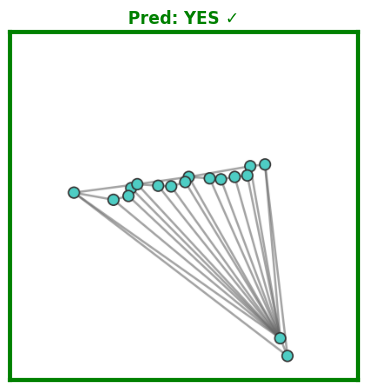


🤖 RESPONSE:
YES: The graph can be drawn in a plane without any edge crossings. Each node is connected to the central node by a straight line, and all lines are parallel to each other, ensuring that no two lines intersect.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.
- NO if: BOLD edges highlight K₅ (pentagon with all diagonals) or K₃,₃ (bipartite 3+3) minor proving non-planarity.

Question: Does this graph have Planarity? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


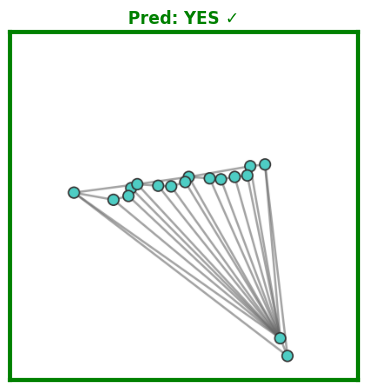


🤖 RESPONSE:
YES: The graph is planar because it can be drawn in a plane without any edges crossing.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.
- NO if: Same spread layout style as YES, but some edges visibly CROSS each other (non-planar edges).

Question: Does this graph have Planarity? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


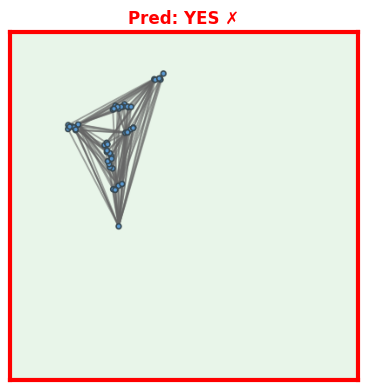


🤖 RESPONSE:
YES: The graph has a planar embedding with zero edge crossings and clean spread layout, meaning there are no lines intersecting.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Planarity

Rules:
- YES if: Planar embedding with ZERO edge crossings. Clean spread layout with no lines intersecting.
- NO if: BOLD edges highlight K₅ (pentagon with all diagonals) or K₃,₃ (bipartite 3+3) minor proving non-planarity.

Question: Does this graph have Planarity? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


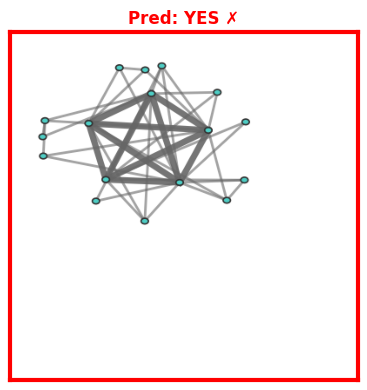


🤖 RESPONSE:
YES: The graph does not contain any subgraph that is a planar representation of K₅ or K₃,₃. It appears to be a clean spread layout without any lines intersecting, indicating it is planar.

████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  OUTER_PLANARITY  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on 

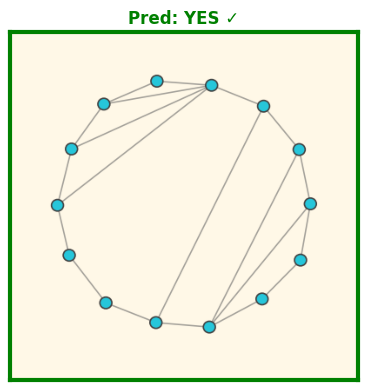


🤖 RESPONSE:
YES: The graph has an outer-planar embedding where all vertices lie on the outer face, and there are no edge crossings.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.
- NO if: BOLD edges highlight K₄ (4 nodes fully connected) or K₂,₃ (2+3 bipartite) minor proving non-outer-planarity.

Question: Does this graph have Outer-Planarity? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


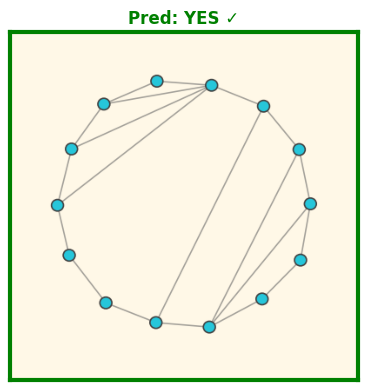


🤖 RESPONSE:
YES: The graph does not contain any subgraph that is a complete subgraph of 4 nodes (K₄) or a complete bipartite subgraph of 2 nodes and 3 nodes (K₂,₃). Therefore, it can be embedded in the plane without any edge crossings, making it outer-planar.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.
- NO if: Outer-planar style layout but some edges visibly CROSS each other.

Question: Does this graph have Outer-Planarity? Answer YES or NO with b

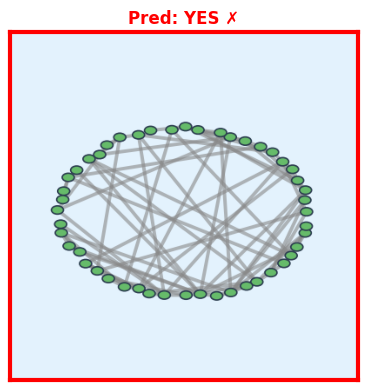


🤖 RESPONSE:
YES: The graph has an outer-planar embedding where all vertices lie on the outer face, and there are no edge crossings.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Outer-Planarity

Rules:
- YES if: Outer-planar embedding with ALL vertices on outer face and ZERO edge crossings.
- NO if: BOLD edges highlight K₄ (4 nodes fully connected) or K₂,₃ (2+3 bipartite) minor proving non-outer-planarity.

Question: Does this graph have Outer-Planarity? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


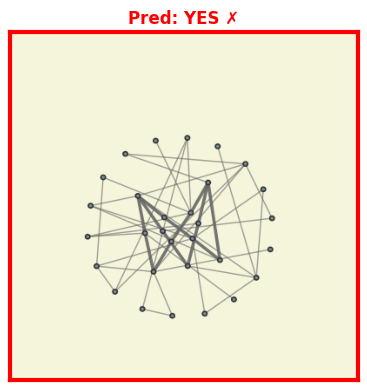


🤖 RESPONSE:
YES: The graph does not contain any subgraph that is a complete subgraph of 4 nodes (K₄) or a complete bipartite subgraph of 2+3 nodes (K₂,₃). Therefore, it can be embedded in the plane without any edge crossings, making it outer-planar.

████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  HAMILTONIAN  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES 

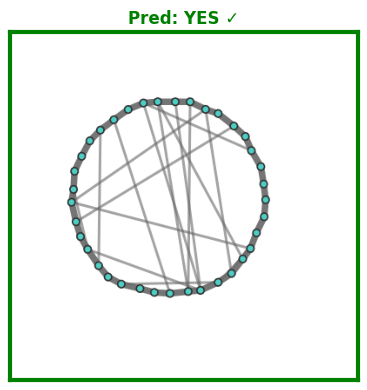


🤖 RESPONSE:
YES: The graph has a Hamiltonian cycle. All nodes are visited in a continuous path that forms a cycle around the outer circle, and the bold highlighted edges connect all nodes without any node being inside the cycle.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Cut-set (S) shown as BOLD highlighted nodes at center. k(G-S) > |S| proving no Hamiltonian cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


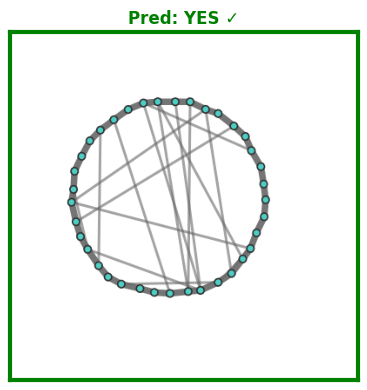


🤖 RESPONSE:
YES: The graph has a Hamiltonian cycle. The outer circle of the graph is a cycle that visits all nodes, and the bold highlighted edges form a Hamiltonian cycle.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Longest cycle on outer circle (LOOKS like Hamiltonian) but some nodes are INSIDE the cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


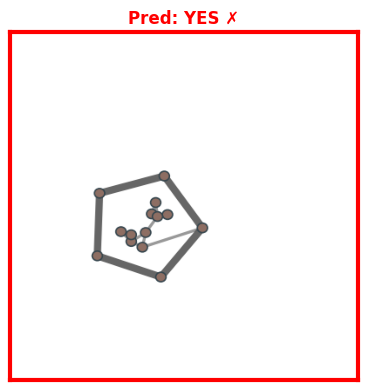


🤖 RESPONSE:
YES: The graph has a Hamiltonian cycle because all nodes are visited in a single cycle that forms a closed loop, even though it looks like a Hamiltonian cycle when viewed from above.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Hamiltonian Cycle

Rules:
- YES if: Hamiltonian cycle on outer circle with BOLD highlighted edges visiting ALL nodes.
- NO if: Cut-set (S) shown as BOLD highlighted nodes at center. k(G-S) > |S| proving no Hamiltonian cycle.

Question: Does this graph have Hamiltonian Cycle? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


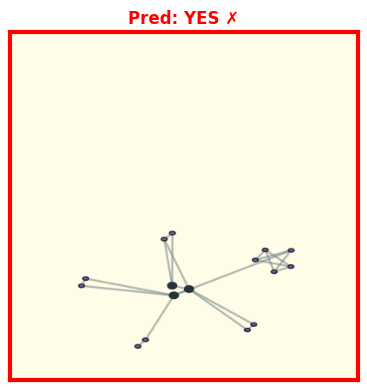


🤖 RESPONSE:
YES: The graph has a Hamiltonian cycle. The highlighted edges form a cycle that visits all nodes, and there is no cut-set (S) shown as bold highlighted nodes at the center, which would indicate a non-Hamiltonian cycle.

████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  K_COLORABILITY  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 

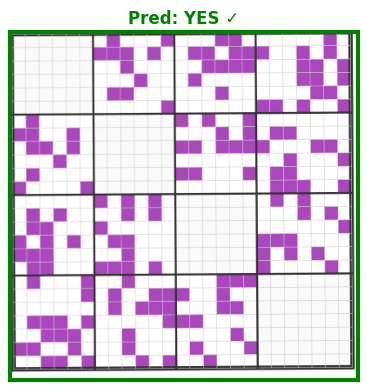


🤖 RESPONSE:
YES: The matrix has only 4 EMPTY diagonal blocks, which is less than the maximum allowed for 4-Colorability. Each block represents an independent set of vertices, and since there are no more than 4 blocks, it is possible to color the graph using at most 4 colors such that no two adjacent vertices share the same color.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.
- NO if: Matrix with highlighted K₅/K₆/K₇/K₈ clique (BOLD highlighted edges forming complete subgraph in top-left block). Except diagonal, every cell in top-left block is filled, showing large clique.

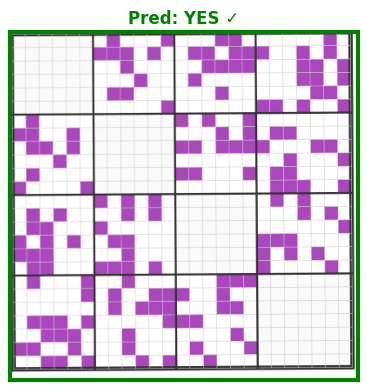


🤖 RESPONSE:
YES: The matrix has no K₅/K₆/K₇/K₈ cliques. Each diagonal block is completely empty and there are no large cliques formed by the highlighted edges. Therefore, it satisfies the condition for 4-Colorability.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.
- NO if: Matrix with >4 EMPTY diagonal blocks (5-8 blocks visible on diagonal), needs more than 4 colors.

Question: Does this graph have 4-Col

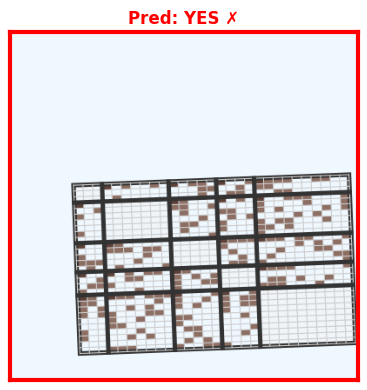


🤖 RESPONSE:
YES: The matrix has only 4 EMPTY diagonal blocks, which is less than the maximum allowed for 4-Colorability. Each block represents an independent set of vertices, and since there are no more than 4 blocks, it can be colored using at most 4 colors.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: 4-Colorability

Rules:
- YES if: Matrix with ≤4 EMPTY diagonal blocks. Each block = one color class (independent set). Every diagonal block is completely empty.
- NO if: Matrix with highlighted K₅/K₆/K₇/K₈ clique (BOLD highlighted edges forming complete subgraph in top-left block). Except diagonal, every cell in top-left block is filled, showing large clique.

Question: Does this graph have 4-Colorability? Answer YES or NO with b

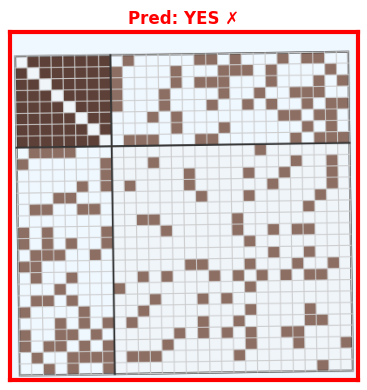


🤖 RESPONSE:
YES: The matrix has only one diagonal block that is completely empty and does not form any large clique. Therefore, it satisfies the condition for 4-colorability.

████████████████████████████████████████████████████████████████████████████████
██████████████████████████████  COMPLETENESS  ██████████████████████████████
████████████████████████████████████████████████████████████████████████████████

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: YES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1 (s_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 200  |  ❌ Wrong: 0  |  Total: 200

📝 PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between e

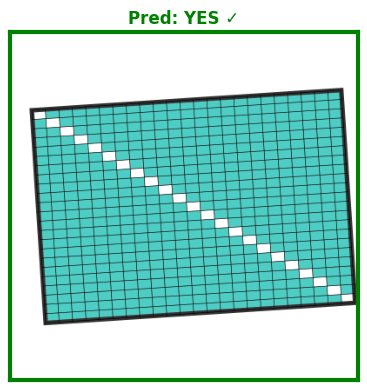


🤖 RESPONSE:
YES: The graph has Graph Completeness because there are no empty cells outside the diagonal, indicating that all edges between every pair of nodes are present.

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2 (d_no rules)                                                    │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 7  |  ❌ Wrong: 193  |  Total: 200

📝 PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).
- NO if: Nodes are sorted by degree (most connected to least). Matrix shows density gradient: dense/filled top-left region fading to sparse/empty bottom-right, proving that not all node pairs are connected.

Question: Does this graph have Graph Completeness? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


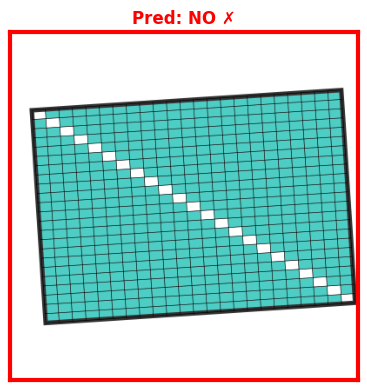


🤖 RESPONSE:
NO: The graph does not have Graph Completeness because the matrix shows a density gradient, indicating that not all node pairs are connected. The top-left region is denser and more filled compared to the bottom-right region, suggesting that some nodes are more connected than others.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ROW: NO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp1] Exp1: s_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 0  |  ❌ Wrong: 200  |  Total: 200

📝 PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).
- NO if: There are some missing edges (empty cells ou

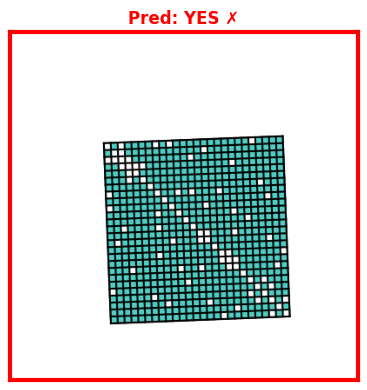


🤖 RESPONSE:
YES: The graph has full adjacency matrix with all cells filled and all edges present between every pair of nodes, except for the diagonal cells which are empty (no self-loops).

┌────────────────────────────────────────────────────────────────────────────┐
│  [Exp2] Exp2: d_no                                                           │
└────────────────────────────────────────────────────────────────────────────┘
✅ Correct: 194  |  ❌ Wrong: 6  |  Total: 200

📝 PROMPT:
Property: Graph Completeness

Rules:
- YES if: Full adjacency matrix - ALL cells filled, all edges present between every pair of nodes. Only diagonal cells are empty (no self-loops).
- NO if: Nodes are sorted by degree (most connected to least). Matrix shows density gradient: dense/filled top-left region fading to sparse/empty bottom-right, proving that not all node pairs are connected.

Question: Does this graph have Graph Completeness? Answer YES or NO with brief reason.

Format: YES/NO: [brief reason]


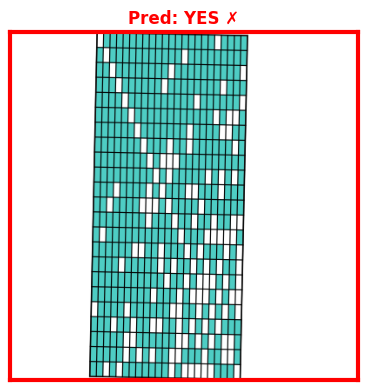


🤖 RESPONSE:
YES: The graph is fully complete as it has no empty diagonal cells and all cells are filled, indicating that every edge exists between every pair of nodes.


In [11]:
# ============================================================================
# STEP 9.1: Per-Property Results - 2x2 Matrix (Exp1 vs Exp2, YES vs NO)
# ============================================================================

df_exp1 = pd.DataFrame(results_same)
df_exp2 = pd.DataFrame(results_diff)

def get_counts(df, prop, sample_type):
    """Get correct/wrong/total counts."""
    subset = df[(df['property'] == prop) & (df['sample_type'] == sample_type)]
    if len(subset) == 0:
        return 0, 0, 0
    expected = 1 if sample_type == 'yes' else 0
    correct = (subset['pred_label'] == expected).sum()
    wrong = len(subset) - correct
    return correct, wrong, len(subset)

def get_example(df, prop, sample_type, prefer_wrong=True):
    """Get example result."""
    subset = df[(df['property'] == prop) & (df['sample_type'] == sample_type)]
    if len(subset) == 0:
        return None, None
    expected = 1 if sample_type == 'yes' else 0
    wrong = subset[subset['pred_label'] != expected]
    correct = subset[subset['pred_label'] == expected]
    if prefer_wrong and len(wrong) > 0:
        return wrong.iloc[0].to_dict(), False
    elif len(correct) > 0:
        return correct.iloc[0].to_dict(), True
    elif len(wrong) > 0:
        return wrong.iloc[0].to_dict(), False
    return None, None

def show_cell(exp_name, row_type, df, sample_type, prop):
    """Display one cell: counts → prompt → image → response."""
    c, w, t = get_counts(df, prop, sample_type)
    result, is_correct = get_example(df, prop, sample_type, prefer_wrong=True)
    
    expected = 'YES' if sample_type == 'yes' else 'NO'
    status = '✓' if is_correct else '✗'
    color = 'green' if is_correct else 'red'
    
    # 1. Counts
    print(f"✅ Correct: {c}  |  ❌ Wrong: {w}  |  Total: {t}")
    
    if result:
        # 2. Prompt
        print(f"\n📝 PROMPT:")
        print(result.get('prompt', 'N/A'))
        
        # 3. Image
        if os.path.exists(result['image_path']):
            fig, ax = plt.subplots(figsize=(5, 4))
            ax.imshow(Image.open(result['image_path']))
            ax.set_title(f"Pred: {result['prediction']} {status}", color=color, fontweight='bold')
            for spine in ax.spines.values():
                spine.set_color(color)
                spine.set_linewidth(3)
            ax.set_xticks([])
            ax.set_yticks([])
            plt.tight_layout()
            plt.show()
        
        # 4. Response
        resp = result.get('response', 'N/A')
        resp = resp[:500] + '...' if len(resp) > 500 else resp
        print(f"\n🤖 RESPONSE:")
        print(resp)
    else:
        print("No sample available.")

def show_property_table(prop):
    """Show 2x2 matrix for one property."""
    print(f"\n{'█'*80}")
    print(f"{'█'*30}  {prop.upper()}  {'█'*30}")
    print(f"{'█'*80}")
    
    # Matrix structure: rows=YES/NO, cols=Exp1/Exp2
    matrix = [
        [('YES', df_exp1, 'yes', 'Exp1 (s_no rules)'), ('YES', df_exp2, 'yes', 'Exp2 (d_no rules)')],
        [('NO',  df_exp1, 's_no', 'Exp1: s_no'),       ('NO',  df_exp2, 'd_no', 'Exp2: d_no')],
    ]
    
    for row_idx, row in enumerate(matrix):
        row_label = 'YES' if row_idx == 0 else 'NO'
        print(f"\n{'━'*80}")
        print(f"ROW: {row_label}")
        print(f"{'━'*80}")
        
        for col_idx, (rtype, df, stype, title) in enumerate(row):
            col_label = 'Exp1' if col_idx == 0 else 'Exp2'
            print(f"\n┌{'─'*76}┐")
            print(f"│  [{col_label}] {title:<68} │")
            print(f"└{'─'*76}┘")
            show_cell(col_label, rtype, df, stype, prop)

# Run for all properties
for prop in config.ALL_PROPERTIES:
    show_property_table(prop)

## 📊 Step 10: Calculate Metrics

Compare **Same Layout** vs **Different Layout** performance.
Visual Proof Gain = Acc(Different) - Acc(Same)

In [12]:
# ============================================================================
# STEP 10: Calculate Metrics (COMPARISON: Exp1 vs Exp2)
# ============================================================================

def compute_metrics(df):
    """Compute metrics for an experiment."""
    df_valid = df[df['pred_label'] != -1]
    y_true, y_pred = df_valid['true_label'].values, df_valid['pred_label'].values
    
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'n_samples': len(df_valid)
    }
    
    per_prop = {}
    for prop in config.ALL_PROPERTIES:
        prop_df = df_valid[df_valid['property'] == prop]
        if len(prop_df) > 0:
            per_prop[prop] = {
                'accuracy': accuracy_score(prop_df['true_label'], prop_df['pred_label']),
                'f1': f1_score(prop_df['true_label'], prop_df['pred_label'], zero_division=0),
                'n': len(prop_df)
            }
    
    return metrics, per_prop, df_valid

metrics_exp1, per_prop_exp1, df_exp1_valid = compute_metrics(df_exp1)
metrics_exp2, per_prop_exp2, df_exp2_valid = compute_metrics(df_exp2)

print("="*60)
print("🔬 COMPARISON: Experiment 1 (s_no) vs Experiment 2 (d_no)")
print("="*60)

print(f"\n{'Metric':<12} {'Exp1 (s_no)':<15} {'Exp2 (d_no)':<15} {'Δ (Exp2-Exp1)':<15}")
print("-" * 57)
for m in ['accuracy', 'precision', 'recall', 'f1']:
    delta = metrics_exp2[m] - metrics_exp1[m]
    print(f"{m:<12} {metrics_exp1[m]:<15.4f} {metrics_exp2[m]:<15.4f} {delta:+.4f}")

visual_proof_gain = metrics_exp2['accuracy'] - metrics_exp1['accuracy']
print(f"\n📊 Visual Proof Gain: {visual_proof_gain:+.4f}")
if visual_proof_gain > 0.05:
    print("✅ d_no significantly easier to detect!")
elif visual_proof_gain > 0:
    print("⚠️ Slight improvement with d_no")
else:
    print("❌ No improvement with d_no")

🔬 COMPARISON: Experiment 1 (s_no) vs Experiment 2 (d_no)

Metric       Exp1 (s_no)     Exp2 (d_no)     Δ (Exp2-Exp1)  
---------------------------------------------------------
accuracy     0.5000          0.5003          +0.0003
precision    0.5000          0.5002          +0.0002
recall       1.0000          0.8794          -0.1206
f1           0.6667          0.6377          -0.0290

📊 Visual Proof Gain: +0.0003
⚠️ Slight improvement with d_no


## 🔍 Step 10.1: Per-Property Comparison

Compare accuracy per property between Same and Different layouts.

In [13]:
# ============================================================================
# STEP 10.1: Per-Property Comparison
# ============================================================================

print("="*60)
print("PER-PROPERTY COMPARISON")
print("="*60)

print(f"\n{'Property':<18} {'Exp1 (s_no)':<12} {'Exp2 (d_no)':<12} {'Δ':<10}")
print("-" * 52)
for prop in config.ALL_PROPERTIES:
    exp1_acc = per_prop_exp1.get(prop, {}).get('accuracy', 0)
    exp2_acc = per_prop_exp2.get(prop, {}).get('accuracy', 0)
    delta = exp2_acc - exp1_acc
    indicator = "✅" if delta > 0.1 else "⚠️" if delta > 0 else "❌"
    print(f"{prop:<18} {exp1_acc:<12.4f} {exp2_acc:<12.4f} {delta:+.4f} {indicator}")

PER-PROPERTY COMPARISON

Property           Exp1 (s_no)  Exp2 (d_no)  Δ         
----------------------------------------------------
cut_vertex         0.5000       0.5000       +0.0000 ❌
connectivity       0.5000       0.5000       +0.0000 ❌
bipartite          0.5000       0.5000       +0.0000 ❌
planarity          0.5000       0.5000       +0.0000 ❌
outer_planarity    0.5000       0.5000       +0.0000 ❌
hamiltonian        0.5000       0.5000       +0.0000 ❌
k_colorability     0.5000       0.5000       +0.0000 ❌
completeness       0.5000       0.5025       +0.0025 ⚠️


## 📈 Step 11: Visualize Results

Charts comparing Same vs Different Layout performance.

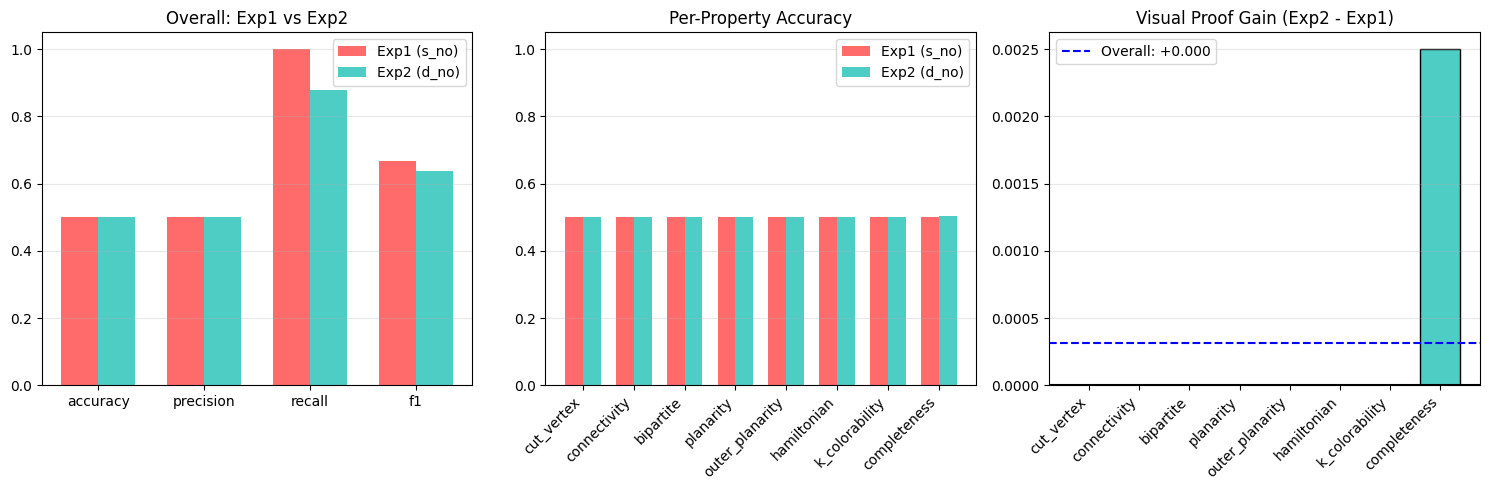

In [14]:
# ============================================================================
# STEP 11: Visualize Results (Exp1 vs Exp2)
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1: Overall comparison bar chart
ax1 = axes[0]
metrics_list = ['accuracy', 'precision', 'recall', 'f1']
x = np.arange(len(metrics_list))
width = 0.35
ax1.bar(x - width/2, [metrics_exp1[m] for m in metrics_list], width, label='Exp1 (s_no)', color='#FF6B6B')
ax1.bar(x + width/2, [metrics_exp2[m] for m in metrics_list], width, label='Exp2 (d_no)', color='#4ECDC4')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics_list)
ax1.set_ylim(0, 1.05)
ax1.legend()
ax1.set_title('Overall: Exp1 vs Exp2')
ax1.grid(axis='y', alpha=0.3)

# 2: Per-property accuracy comparison
ax2 = axes[1]
props = list(per_prop_exp1.keys())
exp1_accs = [per_prop_exp1[p]['accuracy'] for p in props]
exp2_accs = [per_prop_exp2.get(p, {}).get('accuracy', 0) for p in props]
x = np.arange(len(props))
ax2.bar(x - width/2, exp1_accs, width, label='Exp1 (s_no)', color='#FF6B6B')
ax2.bar(x + width/2, exp2_accs, width, label='Exp2 (d_no)', color='#4ECDC4')
ax2.set_xticks(x)
ax2.set_xticklabels(props, rotation=45, ha='right')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.set_title('Per-Property Accuracy')
ax2.grid(axis='y', alpha=0.3)

# 3: Visual Proof Gain per property
ax3 = axes[2]
gains = [exp2_accs[i] - exp1_accs[i] for i in range(len(props))]
colors = ['#4ECDC4' if g >= 0 else '#FF6B6B' for g in gains]
ax3.bar(props, gains, color=colors, edgecolor='black')
ax3.axhline(y=0, color='black', linestyle='-')
ax3.axhline(y=visual_proof_gain, color='blue', linestyle='--', label=f'Overall: {visual_proof_gain:+.3f}')
ax3.set_xticklabels(props, rotation=45, ha='right')
ax3.legend()
ax3.set_title('Visual Proof Gain (Exp2 - Exp1)')
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(config.RESULTS_DIR, 'mllm_exp_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

## 🔲 Step 12: Confusion Matrices

Side-by-side confusion matrices for Same vs Different layouts.

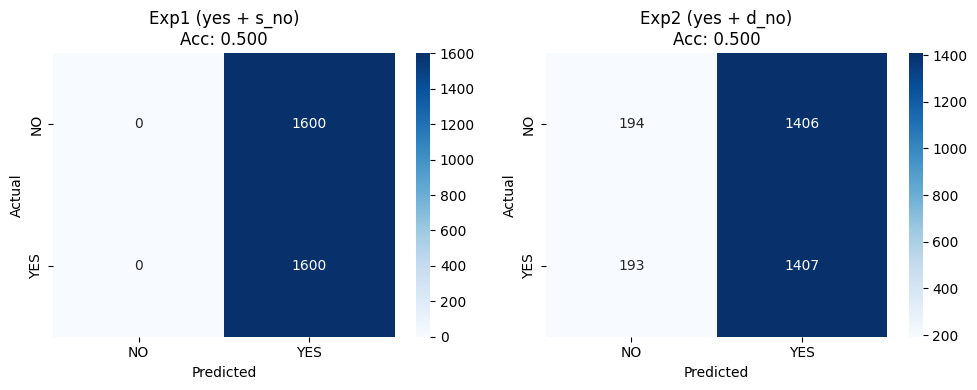

In [15]:
# ============================================================================
# STEP 12: Confusion Matrices (Exp1 vs Exp2)
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for idx, (df, name) in enumerate([(df_exp1_valid, 'Exp1 (yes + s_no)'), (df_exp2_valid, 'Exp2 (yes + d_no)')]):
    ax = axes[idx]
    cm = confusion_matrix(df['true_label'], df['pred_label'], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['NO', 'YES'], yticklabels=['NO', 'YES'])
    acc = accuracy_score(df['true_label'], df['pred_label'])
    ax.set_title(f'{name}\nAcc: {acc:.3f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig(os.path.join(config.RESULTS_DIR, 'mllm_confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()

## 💾 Step 13: Save Results

Export all results for future analysis:
- CSV file with per-property metrics
- JSON file with detailed predictions
- Ready for comparison with trained models

In [16]:
# ============================================================================
# STEP 13: Save Results
# ============================================================================

final_results = {
    'model': config.MODEL_NAME,
    'exp1_s_no': {'metrics': metrics_exp1, 'per_property': per_prop_exp1},
    'exp2_d_no': {'metrics': metrics_exp2, 'per_property': per_prop_exp2},
    'visual_proof_gain': visual_proof_gain
}

with open(os.path.join(config.RESULTS_DIR, 'mllm_results.json'), 'w') as f:
    json.dump(final_results, f, indent=2)

pd.DataFrame(results_same).to_csv(os.path.join(config.RESULTS_DIR, 'mllm_exp1_s_no.csv'), index=False)
pd.DataFrame(results_diff).to_csv(os.path.join(config.RESULTS_DIR, 'mllm_exp2_d_no.csv'), index=False)

print(f"✓ Results saved to {config.RESULTS_DIR}/")

✓ Results saved to ./mllm_eval_results/


## 🔄 Step 14: Compare with Trained Models

Compare MLLM baseline performance against trained CNN/GNN models.  
This establishes how well a general-purpose vision-language model performs  
**without any task-specific training** on graph property classification.

In [17]:
# ============================================================================
# STEP 14: Compare with Trained Models (Optional)
# ============================================================================

trained_results_path = './results/final_results.json'

if os.path.exists(trained_results_path):
    with open(trained_results_path, 'r') as f:
        trained_results = json.load(f)
    
    print("="*70)
    print("COMPARISON: MLLM vs Trained Models")
    print("="*70)
    
    # Use Exp2 (d_no) as MLLM baseline (fairer comparison with visual proofs)
    comparison_data = [
        {
            'Model': f"MLLM Exp1 (s_no)",
            'Type': 'MLLM (Zero-Shot)',
            'Accuracy': metrics_exp1['accuracy'],
            'F1': metrics_exp1['f1']
        },
        {
            'Model': f"MLLM Exp2 (d_no)",
            'Type': 'MLLM (Zero-Shot)',
            'Accuracy': metrics_exp2['accuracy'],
            'F1': metrics_exp2['f1']
        }
    ]
    
    for model_name, model_data in trained_results.get('models', {}).items():
        comparison_data.append({
            'Model': model_data.get('display_name', model_name),
            'Type': model_data.get('type', 'Unknown') + ' (Trained)',
            'Accuracy': model_data.get('overall', {}).get('accuracy', 0),
            'F1': model_data.get('overall', {}).get('f1', 0)
        })
    
    df_comparison = pd.DataFrame(comparison_data).sort_values('F1', ascending=False)
    print(df_comparison.to_string(index=False))
else:
    print(f"Trained model results not found at: {trained_results_path}")

Trained model results not found at: ./results/final_results.json


---

## 📋 Summary

### Two Experiments:
1. **Exp1** (yes + s_no): Tests classification with s_no negatives
2. **Exp2** (yes + d_no): Tests classification with d_no negatives

### Key Metric:
**Visual Proof Gain** = Acc(Exp2) - Acc(Exp1)
- Positive gain → d_no easier to detect
- Negative gain → s_no easier to detect

In [18]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

print("="*60)
print("MLLM EVALUATION - FINAL SUMMARY")
print("="*60)
print(f"\nModel: {config.MODEL_NAME.split('/')[-1]}")
print(f"\n--- Exp1 (yes + s_no) ---")
print(f"Accuracy: {metrics_exp1['accuracy']:.4f}, F1: {metrics_exp1['f1']:.4f}")
print(f"\n--- Exp2 (yes + d_no) ---")
print(f"Accuracy: {metrics_exp2['accuracy']:.4f}, F1: {metrics_exp2['f1']:.4f}")
print(f"\n📊 Visual Proof Gain: {visual_proof_gain:+.4f}")
print("="*60)

MLLM EVALUATION - FINAL SUMMARY

Model: Qwen2.5-VL-3B-Instruct

--- Exp1 (yes + s_no) ---
Accuracy: 0.5000, F1: 0.6667

--- Exp2 (yes + d_no) ---
Accuracy: 0.5003, F1: 0.6377

📊 Visual Proof Gain: +0.0003
